In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [21]:
import sys
print(sys.executable)

/Users/kaushal/quant_trading_project/.venv/bin/python


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [23]:
import yfinance as yf
eurusd = yf.download("EURUSD=X", period="2y", interval="1h", auto_adjust=False)
eurusd

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,EURUSD=X,EURUSD=X,EURUSD=X,EURUSD=X,EURUSD=X,EURUSD=X
Datetime,,,,,,
2024-11-18 00:00:00+00:00,1.055186,1.055186,1.055298,1.053741,1.053963,0
2024-11-18 01:00:00+00:00,1.054407,1.054407,1.055186,1.054185,1.055075,0
2024-11-18 02:00:00+00:00,1.054519,1.054519,1.054852,1.054074,1.054519,0
2024-11-18 03:00:00+00:00,1.053741,1.053741,1.054741,1.053408,1.054407,0
2024-11-18 04:00:00+00:00,1.054407,1.054407,1.054519,1.053630,1.053630,0
...,...,...,...,...,...,...
2026-11-16 13:00:00+00:00,1.101443,1.101443,1.101807,1.101200,1.101686,0
2026-11-16 14:00:00+00:00,1.100715,1.100715,1.101807,1.100715,1.101564,0


In [24]:
eurusd.shape


(12289, 6)

In [25]:
eurusd.columns

MultiIndex([('Adj Close', 'EURUSD=X'),
            (    'Close', 'EURUSD=X'),
            (     'High', 'EURUSD=X'),
            (      'Low', 'EURUSD=X'),
            (     'Open', 'EURUSD=X'),
            (   'Volume', 'EURUSD=X')],
           names=['Price', 'Ticker'])

In [26]:
eurusd.columns=eurusd.columns.get_level_values("Price")

In [27]:
eurusd.columns.names

FrozenList(['Price'])

In [28]:
print(eurusd.columns)

Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='str', name='Price')


In [29]:
eurusd.columns=[column[0] for column in eurusd.columns]

In [30]:
eurusd.columns

Index(['A', 'C', 'H', 'L', 'O', 'V'], dtype='str')

In [31]:
print(eurusd.columns)

Index(['A', 'C', 'H', 'L', 'O', 'V'], dtype='str')


In [32]:
eurusd["C"].head()

Datetime
2024-11-18 00:00:00+00:00    1.055186
2024-11-18 01:00:00+00:00    1.054407
2024-11-18 02:00:00+00:00    1.054519
2024-11-18 03:00:00+00:00    1.053741
2024-11-18 04:00:00+00:00    1.054407
Name: C, dtype: float64

In [33]:
eurusd["C"]

Datetime
2024-11-18 00:00:00+00:00    1.055186
2024-11-18 01:00:00+00:00    1.054407
2024-11-18 02:00:00+00:00    1.054519
2024-11-18 03:00:00+00:00    1.053741
2024-11-18 04:00:00+00:00    1.054407
                               ...   
2026-11-16 13:00:00+00:00    1.101443
2026-11-16 14:00:00+00:00    1.100715
2026-11-16 15:00:00+00:00    1.100837
2026-11-16 16:00:00+00:00    1.100715
2026-11-16 17:00:00+00:00    1.101443
Name: C, Length: 12289, dtype: float64

In [34]:
eurusd.columns=["Adj Close", "Close", "High", "Low", "Open", "Volume"]

In [35]:
eurusd.columns

Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='str')

In [36]:
eurusd["High"]

Datetime
2024-11-18 00:00:00+00:00    1.055298
2024-11-18 01:00:00+00:00    1.055186
2024-11-18 02:00:00+00:00    1.054852
2024-11-18 03:00:00+00:00    1.054741
2024-11-18 04:00:00+00:00    1.054519
                               ...   
2026-11-16 13:00:00+00:00    1.101807
2026-11-16 14:00:00+00:00    1.101807
2026-11-16 15:00:00+00:00    1.102050
2026-11-16 16:00:00+00:00    1.101443
2026-11-16 17:00:00+00:00    1.101443
Name: High, Length: 12289, dtype: float64

In [37]:
eurusd["Return"]=eurusd["Close"].pct_change()
eurusd["Return"]

Datetime
2024-11-18 00:00:00+00:00         NaN
2024-11-18 01:00:00+00:00   -0.000738
2024-11-18 02:00:00+00:00    0.000105
2024-11-18 03:00:00+00:00   -0.000738
2024-11-18 04:00:00+00:00    0.000633
                               ...   
2026-11-16 13:00:00+00:00   -0.000220
2026-11-16 14:00:00+00:00   -0.000661
2026-11-16 15:00:00+00:00    0.000110
2026-11-16 16:00:00+00:00   -0.000110
2026-11-16 17:00:00+00:00    0.000661
Name: Return, Length: 12289, dtype: float64

In [38]:
eurusd[["Close","Return"]].head(10)

,Close,Return
Datetime,,
2024-11-18 00:00:00+00:00,1.055186,NaN
2024-11-18 01:00:00+00:00,1.054407,-0.000738
2024-11-18 02:00:00+00:00,1.054519,0.000105
2024-11-18 03:00:00+00:00,1.053741,-0.000738
2024-11-18 04:00:00+00:00,1.054407,0.000633
2024-11-18 05:00:00+00:00,1.054074,-0.000316
2024-11-18 06:00:00+00:00,1.054519,0.000422
2024-11-18 07:00:00+00:00,1.054852,0.000316
2024-11-18 08:00:00+00:00,1.055075,0.000211


In [39]:
eurusd["Return"].describe()

count    12288.000000
mean         0.000004
std          0.000917
min         -0.012687
25%         -0.000353
50%          0.000000
75%          0.000352
max          0.012008
Name: Return, dtype: float64

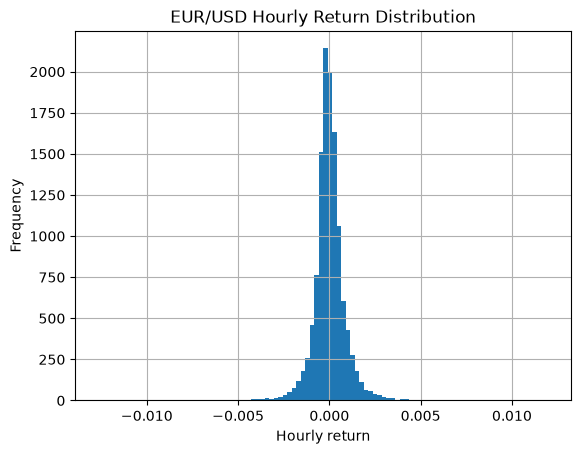

In [40]:
eurusd["Return"].hist(bins=100)
plt.xlabel("Hourly return")
plt.ylabel("Frequency")
plt.title("EUR/USD Hourly Return Distribution")
plt.show()

In [41]:
eurusd["Return"].skew()

np.float64(-0.030115698147513994)

In [42]:
eurusd["Return"].kurt()

np.float64(16.90651603196364)

In [43]:
eurusd["SMA20"]=eurusd["Close"].rolling(window=20).mean()

In [44]:
eurusd[["Close", "SMA20"]].tail(10)

,Close,SMA20
Datetime,,
2026-11-16 08:00:00+00:00,1.102901,1.103048
2026-11-16 09:00:00+00:00,1.101322,1.102847
2026-11-16 10:00:00+00:00,1.100715,1.102610
2026-11-16 11:00:00+00:00,1.101322,1.102372
2026-11-16 12:00:00+00:00,1.101686,1.102305
2026-11-16 13:00:00+00:00,1.101443,1.102196
2026-11-16 14:00:00+00:00,1.100715,1.102081
2026-11-16 15:00:00+00:00,1.100837,1.101965
2026-11-16 16:00:00+00:00,1.100715,1.101862


In [45]:
eurusd["SMA20_Distance"]=(eurusd["Close"]-eurusd["SMA20"])/eurusd["SMA20"]

In [46]:
eurusd[["Close", "SMA20", "SMA20_Distance"]].tail(10)

,Close,SMA20,SMA20_Distance
Datetime,,,
2026-11-16 08:00:00+00:00,1.102901,1.103048,-0.000134
2026-11-16 09:00:00+00:00,1.101322,1.102847,-0.001383
2026-11-16 10:00:00+00:00,1.100715,1.102610,-0.001718
2026-11-16 11:00:00+00:00,1.101322,1.102372,-0.000953
2026-11-16 12:00:00+00:00,1.101686,1.102305,-0.000562
2026-11-16 13:00:00+00:00,1.101443,1.102196,-0.000683
2026-11-16 14:00:00+00:00,1.100715,1.102081,-0.001239
2026-11-16 15:00:00+00:00,1.100837,1.101965,-0.001024
2026-11-16 16:00:00+00:00,1.100715,1.101862,-0.001041


In [47]:
eurusd[["Close", "SMA20", "SMA20_Distance"]].tail(10)


,Close,SMA20,SMA20_Distance
Datetime,,,
2026-11-16 08:00:00+00:00,1.102901,1.103048,-0.000134
2026-11-16 09:00:00+00:00,1.101322,1.102847,-0.001383
2026-11-16 10:00:00+00:00,1.100715,1.102610,-0.001718
2026-11-16 11:00:00+00:00,1.101322,1.102372,-0.000953
2026-11-16 12:00:00+00:00,1.101686,1.102305,-0.000562
2026-11-16 13:00:00+00:00,1.101443,1.102196,-0.000683
2026-11-16 14:00:00+00:00,1.100715,1.102081,-0.001239
2026-11-16 15:00:00+00:00,1.100837,1.101965,-0.001024
2026-11-16 16:00:00+00:00,1.100715,1.101862,-0.001041


In [48]:
eurusd[["Close", "SMA20", "SMA20_Distance"]].tail(10)


,Close,SMA20,SMA20_Distance
Datetime,,,
2026-11-16 08:00:00+00:00,1.102901,1.103048,-0.000134
2026-11-16 09:00:00+00:00,1.101322,1.102847,-0.001383
2026-11-16 10:00:00+00:00,1.100715,1.102610,-0.001718
2026-11-16 11:00:00+00:00,1.101322,1.102372,-0.000953
2026-11-16 12:00:00+00:00,1.101686,1.102305,-0.000562
2026-11-16 13:00:00+00:00,1.101443,1.102196,-0.000683
2026-11-16 14:00:00+00:00,1.100715,1.102081,-0.001239
2026-11-16 15:00:00+00:00,1.100837,1.101965,-0.001024
2026-11-16 16:00:00+00:00,1.100715,1.101862,-0.001041


In [49]:
eurusd["SMA20_Distance"].describe()

count    12270.000000
mean         0.000033
std          0.002230
min         -0.014173
25%         -0.001136
50%         -0.000075
75%          0.001130
max          0.015221
Name: SMA20_Distance, dtype: float64

In [50]:
eurusd["Future_Return_1H"]=eurusd["Close"].pct_change().shift(-1)

In [51]:
eurusd["SMA20_Distance"].std()

np.float64(0.0022304053304151245)

In [52]:
eurusd["Extreme_Low"]=eurusd["SMA20_Distance"] < - eurusd["SMA20_Distance"].std()

In [53]:
eurusd["Extreme_Low"].value_counts()

Extreme_Low
False    10991
True      1298
Name: count, dtype: int64

In [54]:
eurusd.loc[eurusd["Extreme_Low"],"Future_Return_1H"].mean()

np.float64(8.183250491752463e-05)

In [55]:
eurusd.loc[eurusd["Extreme_Low"],"Future_Return_1H"].std()

np.float64(0.0011576909256229978)

In [56]:
import yfinance as yf

eurusd = yf.download(
    "EURUSD=X",
    period="2y",
    interval="1h",
    auto_adjust=False
)

eurusd.columns = [column[0] for column in eurusd.columns]

eurusd.columns = ["Adj Close", "Close", "High", "Low", "Open", "Volume"]

eurusd["Return"] = eurusd["Close"].pct_change()

eurusd["SMA20"] = eurusd["Close"].rolling(window=20).mean()

eurusd["SMA20_Distance"] = (
    eurusd["Close"] - eurusd["SMA20"]
) / eurusd["SMA20"]

eurusd["Future_Return_1H"] = eurusd["Close"].pct_change().shift(-1)

eurusd["Extreme_Low"] = (
    eurusd["SMA20_Distance"] < -eurusd["SMA20_Distance"].std()
)

[*********************100%***********************]  1 of 1 completed


In [57]:
eurusd.loc[eurusd["Extreme_Low"],"Future_Return_1H"].std()


np.float64(0.0011576909256229978)

In [58]:
(0.001181876516665926)/np.sqrt(1301)

np.float64(3.276675660937804e-05)

In [59]:
6.862026696851688e-05 / 3.276675660937804e-05

2.094203823300514

In [60]:
eurusd.loc[eurusd["Extreme_Low"], "Future_Return_1H"].describe()

count    1298.000000
mean        0.000082
std         0.001158
min        -0.012687
25%        -0.000413
50%         0.000116
75%         0.000619
max         0.006010
Name: Future_Return_1H, dtype: float64

In [61]:
eurusd.loc[eurusd["Extreme_Low"],"Future_Return_1H"].gt(0).mean()

np.float64(0.5416024653312789)

In [62]:
eurusd["Future_Return_1H"].gt(0).mean()

np.float64(0.4530881275937831)

In [63]:
extreme_low_win_rate = eurusd.loc[eurusd["Extreme_Low"],"Future_Return_1H"].gt(0).mean()
overall_win_rate = eurusd["Future_Return_1H"].gt(0).mean()
difference = extreme_low_win_rate - overall_win_rate
difference

np.float64(0.08851433773749579)

In [64]:
p = overall_win_rate
n = eurusd["Future_Return_1H"].notna().sum()
se = np.sqrt(p*(1-p)/n)
se

np.float64(0.004490652149101551)

In [65]:
p1 = extreme_low_win_rate
n1 = eurusd["Extreme_Low"].sum()
se1 = np.sqrt(p1*(1-p1)/n1)
se1

np.float64(0.013830061351227099)

In [66]:
se_difference = np.sqrt(se**2 + se1**2)
se_difference

np.float64(0.014540858080008068)

In [67]:
z = difference / se_difference
z

np.float64(6.087284343913126)

In [68]:
non_extreme_low_win_rate = eurusd.loc[~eurusd["Extreme_Low"],"Future_Return_1H"].gt(0).mean()
non_extreme_low_win_rate

np.float64(0.4426348830861614)

In [69]:
extreme_count = eurusd["Extreme_Low"].sum()
non_extreme_count = (~eurusd["Extreme_Low"]).sum()
extreme_count,non_extreme_count

(np.int64(1298), np.int64(10991))

In [70]:
p2 = non_extreme_low_win_rate
n2 = non_extreme_count
se2 = np.sqrt(p2*(1-p2)/n2)
se2

np.float64(0.004737771452203523)

In [71]:
se_diff = np.sqrt(se1**2 + se2**2)
se_diff

np.float64(0.014619065473279071)

In [72]:
z_diff = (extreme_low_win_rate - non_extreme_low_win_rate)/se_diff
z_diff

np.float64(6.769761201631649)

In [73]:
eurusd["Extreme_Low"].astype(int).diff().value_counts()

Extreme_Low
 0.0    11634
 1.0      327
-1.0      327
Name: count, dtype: int64

In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# Download EUR/USD hourly data
eurusd = yf.download(
    "EURUSD=X",
    period="2y",
    interval="1h",
    auto_adjust=False
)

# Flatten yfinance MultiIndex columns
eurusd.columns = [column[0] for column in eurusd.columns]

# Make sure column names are correct
eurusd.columns = ["Adj Close", "Close", "High", "Low", "Open", "Volume"]

# Calculate hourly returns
eurusd["Return"] = eurusd["Close"].pct_change()

# Calculate 20-hour moving average
eurusd["SMA20"] = eurusd["Close"].rolling(window=20).mean()

# Calculate distance from SMA20
eurusd["SMA20_Distance"] = (
    eurusd["Close"] - eurusd["SMA20"]
) / eurusd["SMA20"]

# Calculate next-hour return
eurusd["Future_Return_1H"] = (
    eurusd["Close"].pct_change().shift(-1)
)

# Define Extreme_Low
eurusd["Extreme_Low"] = (
    eurusd["SMA20_Distance"]
    < -eurusd["SMA20_Distance"].std()
)

print("EUR/USD data restored successfully.")
print("Rows:", len(eurusd))
print("Extreme_Low observations:", eurusd["Extreme_Low"].sum())

[*********************100%***********************]  1 of 1 completed

EUR/USD data restored successfully.
Rows: 12289
Extreme_Low observations: 1298


In [75]:
groups = eurusd["Extreme_Low"].ne(eurusd["Extreme_Low"].shift()).cumsum()
episode_lengths = eurusd.loc[eurusd["Extreme_Low"]].groupby(groups).size()
episode_lengths.describe()

count    327.000000
mean       3.969419
std        4.037286
min        1.000000
25%        1.000000
50%        2.000000
75%        6.000000
max       20.000000
dtype: float64

In [76]:
eurusd["Episode_Hour"] = (eurusd.loc[eurusd["Extreme_Low"]].groupby(groups).cumcount()+1)

In [77]:
eurusd.loc[eurusd["Extreme_Low"],["Extreme_Low", "Episode_Hour", "Future_Return_1H"]].head(15)

,Extreme_Low,Episode_Hour,Future_Return_1H
Datetime,,,
2024-11-19 09:00:00+00:00,True,1.0,0.000845
2024-11-19 10:00:00+00:00,True,2.0,0.000106
2024-11-19 11:00:00+00:00,True,3.0,0.000952
2024-11-20 08:00:00+00:00,True,1.0,-0.000634
2024-11-20 09:00:00+00:00,True,2.0,-0.000739
2024-11-20 10:00:00+00:00,True,3.0,0.000633
2024-11-20 11:00:00+00:00,True,4.0,0.000317
2024-11-20 12:00:00+00:00,True,5.0,-0.000317
2024-11-20 13:00:00+00:00,True,6.0,-0.002633


In [78]:
eurusd.loc[eurusd["Extreme_Low"],["Extreme_Low", "Episode_Hour", "Future_Return_1H"]].tail(15)

,Extreme_Low,Episode_Hour,Future_Return_1H
Datetime,,,
2026-11-11 18:00:00+00:00,True,7.0,0.000222
2026-11-11 19:00:00+00:00,True,8.0,-0.000333
2026-11-11 20:00:00+00:00,True,9.0,0.000222
2026-11-11 21:00:00+00:00,True,10.0,-0.000111
2026-11-11 22:00:00+00:00,True,11.0,0.000444
2026-11-12 02:00:00+00:00,True,1.0,0.000332
2026-11-12 03:00:00+00:00,True,2.0,0.000332
2026-11-12 16:00:00+00:00,True,1.0,-0.000774
2026-11-12 17:00:00+00:00,True,2.0,0.000221


In [79]:
episode_hour_stats = eurusd.loc[
    eurusd["Extreme_Low"]
].groupby("Episode_Hour")["Future_Return_1H"].agg(
    ["count", "mean", "std"]
)

In [80]:
episode_hour_stats

,count,mean,std
Episode_Hour,,,
1.0,327,0.000036,0.001340
2.0,206,0.000029,0.001423
3.0,151,0.000185,0.001003
4.0,114,-0.000060,0.000918
5.0,95,0.000209,0.001014
6.0,86,0.000133,0.001166
7.0,64,0.000169,0.000913
8.0,52,-0.000069,0.000846
9.0,45,0.000070,0.001195


In [81]:
episode_hour_stats["SE"] = (episode_hour_stats["std"] / np.sqrt(episode_hour_stats["count"]))

In [82]:
episode_hour_stats["t_stat"] = (episode_hour_stats["mean"] / episode_hour_stats["SE"])

In [83]:
episode_hour_stats

,count,mean,std,SE,t_stat
Episode_Hour,,,,,
1.0,327,0.000036,0.001340,0.000074,0.490694
2.0,206,0.000029,0.001423,0.000099,0.295750
3.0,151,0.000185,0.001003,0.000082,2.268343
4.0,114,-0.000060,0.000918,0.000086,-0.699101
5.0,95,0.000209,0.001014,0.000104,2.011914
6.0,86,0.000133,0.001166,0.000126,1.054915
7.0,64,0.000169,0.000913,0.000114,1.478742
8.0,52,-0.000069,0.000846,0.000117,-0.589338
9.0,45,0.000070,0.001195,0.000178,0.395135


In [84]:
groups.head(20)

Datetime
2024-11-18 00:00:00+00:00    1
2024-11-18 01:00:00+00:00    1
2024-11-18 02:00:00+00:00    1
2024-11-18 03:00:00+00:00    1
2024-11-18 04:00:00+00:00    1
2024-11-18 05:00:00+00:00    1
2024-11-18 06:00:00+00:00    1
2024-11-18 07:00:00+00:00    1
2024-11-18 08:00:00+00:00    1
2024-11-18 09:00:00+00:00    1
2024-11-18 10:00:00+00:00    1
2024-11-18 11:00:00+00:00    1
2024-11-18 12:00:00+00:00    1
2024-11-18 13:00:00+00:00    1
2024-11-18 14:00:00+00:00    1
2024-11-18 15:00:00+00:00    1
2024-11-18 16:00:00+00:00    1
2024-11-18 17:00:00+00:00    1
2024-11-18 18:00:00+00:00    1
2024-11-18 19:00:00+00:00    1
Name: Extreme_Low, dtype: int64

In [85]:
first_hour_mask = (eurusd.loc[eurusd["Extreme_Low"]].groupby(groups).cumcount() == 0)

In [86]:
first_hour_mask.head(20)

Datetime
2024-11-19 09:00:00+00:00     True
2024-11-19 10:00:00+00:00    False
2024-11-19 11:00:00+00:00    False
2024-11-20 08:00:00+00:00     True
2024-11-20 09:00:00+00:00    False
2024-11-20 10:00:00+00:00    False
2024-11-20 11:00:00+00:00    False
2024-11-20 12:00:00+00:00    False
2024-11-20 13:00:00+00:00    False
2024-11-20 14:00:00+00:00    False
2024-11-20 15:00:00+00:00    False
2024-11-20 16:00:00+00:00    False
2024-11-20 17:00:00+00:00    False
2024-11-20 18:00:00+00:00    False
2024-11-21 15:00:00+00:00     True
2024-11-21 16:00:00+00:00    False
2024-11-21 17:00:00+00:00    False
2024-11-21 18:00:00+00:00    False
2024-11-21 19:00:00+00:00    False
2024-11-21 20:00:00+00:00    False
dtype: bool

In [87]:
first_hour_returns = eurusd.loc[eurusd["Extreme_Low"]].loc[first_hour_mask, "Future_Return_1H"]

In [88]:
first_hour_returns.describe()

count    327.000000
mean       0.000036
std        0.001340
min       -0.010109
25%       -0.000450
50%        0.000116
75%        0.000693
max        0.003891
Name: Future_Return_1H, dtype: float64

In [89]:
first_hour_se = (first_hour_returns.std() / np.sqrt(first_hour_returns.count()))
first_hour_se

np.float64(7.407582036434243e-05)

In [90]:
episode_t_stat = (first_hour_returns.mean() / first_hour_se)
episode_t_stat

np.float64(0.4906943031888101)

In [91]:
first_hour_win_rate = ((first_hour_returns > 0).mean())
first_hour_win_rate

np.float64(0.5321100917431193)

In [92]:
non_extreme_win_rate = (eurusd.loc[~eurusd["Extreme_Low"],"Future_Return_1H"] > 0).mean()
non_extreme_win_rate

np.float64(0.4426348830861614)

In [93]:
win_rate_difference = (first_hour_win_rate - non_extreme_win_rate)
win_rate_difference

np.float64(0.0894752086569579)

In [94]:
first_hour_count = first_hour_returns.count()
first_hour_count

np.int64(327)

In [95]:
non_extreme_count = (eurusd["Extreme_Low"] == False).sum()
non_extreme_count

np.int64(10991)

In [96]:
extreme_se = np.sqrt(first_hour_win_rate * (1-first_hour_win_rate)/first_hour_count)
extreme_se

np.float64(0.027592986633204628)

In [97]:
non_extreme_se = np.sqrt(non_extreme_win_rate *(1-non_extreme_win_rate)/non_extreme_count)
non_extreme_se

np.float64(0.004737771452203523)

In [98]:
difference_se = np.sqrt(extreme_se **2 + non_extreme_se**2)
difference_se

np.float64(0.027996774629830554)

In [99]:
difference_z = (win_rate_difference / difference_se)
difference_z

np.float64(3.195911309069942)

In [100]:
eurusd.index.hour

Index([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9,
       ...
        8,  9, 10, 11, 12, 13, 14, 15, 16, 17],
      dtype='int32', name='Datetime', length=12289)

In [101]:
eurusd["HourOfDay"] = eurusd.index.hour

In [102]:
eurusd["HourOfDay"].tail(10)

Datetime
2026-11-16 08:00:00+00:00     8
2026-11-16 09:00:00+00:00     9
2026-11-16 10:00:00+00:00    10
2026-11-16 11:00:00+00:00    11
2026-11-16 12:00:00+00:00    12
2026-11-16 13:00:00+00:00    13
2026-11-16 14:00:00+00:00    14
2026-11-16 15:00:00+00:00    15
2026-11-16 16:00:00+00:00    16
2026-11-16 17:00:00+00:00    17
Name: HourOfDay, dtype: int32

In [103]:
baseline_returns = eurusd["Future_Return_1H"].dropna()
baseline_returns.count()


np.int64(12288)

In [104]:
n_episode_starts = first_hour_returns.count()

n_episode_starts

np.int64(327)

In [105]:
rng = np.random.default_rng(42)

In [109]:
random_sample = rng.choice(baseline_returns, size = n_episode_starts, replace = False)
len(random_sample)

327

In [110]:
print("Dataset shape:")
print(eurusd.shape)

print("\nColumn names:")
print(eurusd.columns.tolist())

print("\nFirst 5 rows:")
display(eurusd.head())

print("\nData types:")
print(eurusd.dtypes)

print("\nMissing values:")
print(eurusd.isnull().sum())

Dataset shape:
(12289, 13)

Column names:
['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Return', 'SMA20', 'SMA20_Distance', 'Future_Return_1H', 'Extreme_Low', 'Episode_Hour', 'HourOfDay']

First 5 rows:


,Adj Close,Close,High,Low,Open,Volume,Return,SMA20,SMA20_Distance,Future_Return_1H,Extreme_Low,Episode_Hour,HourOfDay
Datetime,,,,,,,,,,,,,
2024-11-18 00:00:00+00:00,1.055186,1.055186,1.055298,1.053741,1.053963,0,NaN,NaN,NaN,-0.000738,False,NaN,0
2024-11-18 01:00:00+00:00,1.054407,1.054407,1.055186,1.054185,1.055075,0,-0.000738,NaN,NaN,0.000105,False,NaN,1
2024-11-18 02:00:00+00:00,1.054519,1.054519,1.054852,1.054074,1.054519,0,0.000105,NaN,NaN,-0.000738,False,NaN,2
2024-11-18 03:00:00+00:00,1.053741,1.053741,1.054741,1.053408,1.054407,0,-0.000738,NaN,NaN,0.000633,False,NaN,3
2024-11-18 04:00:00+00:00,1.054407,1.054407,1.054519,1.053630,1.053630,0,0.000633,NaN,NaN,-0.000316,False,NaN,4



Data types:
Adj Close           float64
Close               float64
High                float64
Low                 float64
Open                float64
Volume                int64
Return              float64
SMA20               float64
SMA20_Distance      float64
Future_Return_1H    float64
Extreme_Low            bool
Episode_Hour        float64
HourOfDay             int32
dtype: object

Missing values:
Adj Close               0
Close                   0
High                    0
Low                     0
Open                    0
Volume                  0
Return                  1
SMA20                  19
SMA20_Distance         19
Future_Return_1H        1
Extreme_Low             0
Episode_Hour        10991
HourOfDay               0
dtype: int64


In [111]:
# 1. Dataset information
eurusd.info()

# 2. Missing values
print("\nMissing Values:")
print(eurusd.isnull().sum())

# 3. Duplicate timestamps
print("\nDuplicate timestamps:")
print(eurusd.index.duplicated().sum())

# 4. Check chronological order
print("\nChronological order:")
print(eurusd.index.is_monotonic_increasing)

# 5. Statistical summary
print("\nStatistical Summary:")
display(eurusd.describe())

# 6. Volume analysis
print("\nVolume distribution:")
print(eurusd["Volume"].value_counts().head(10))

<class 'pandas.DataFrame'>
DatetimeIndex: 12289 entries, 2024-11-18 00:00:00+00:00 to 2026-11-16 17:00:00+00:00
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Adj Close         12289 non-null  float64
 1   Close             12289 non-null  float64
 2   High              12289 non-null  float64
 3   Low               12289 non-null  float64
 4   Open              12289 non-null  float64
 5   Volume            12289 non-null  int64  
 6   Return            12288 non-null  float64
 7   SMA20             12270 non-null  float64
 8   SMA20_Distance    12270 non-null  float64
 9   Future_Return_1H  12288 non-null  float64
 10  Extreme_Low       12289 non-null  bool   
 11  Episode_Hour      1298 non-null   float64
 12  HourOfDay         12289 non-null  int32  
dtypes: bool(1), float64(10), int32(1), int64(1)
memory usage: 1.4 MB

Missing Values:
Adj Close               0
Close                   0
High       

,Adj Close,Close,High,Low,Open,Volume,Return,SMA20,SMA20_Distance,Future_Return_1H,Episode_Hour,HourOfDay
count,12289.000000,12289.000000,12289.000000,12289.000000,12289.000000,12289.0,12288.000000,12270.000000,12270.000000,12288.000000,1298.000000,12289.000000
mean,1.136470,1.136470,1.137089,1.135862,1.136465,0.0,0.000004,1.136561,0.000033,0.000004,4.531587,11.391895
std,0.044846,0.044846,0.044797,0.044898,0.044852,0.0,0.000917,0.044775,0.002230,0.000917,3.809780,6.869983
min,1.019576,1.019576,1.020408,1.018226,1.019680,0.0,-0.012687,1.021551,-0.014173,-0.012687,1.000000,0.000000
25%,1.122083,1.122083,1.122586,1.121453,1.122083,0.0,-0.000353,1.121946,-0.001136,-0.000353,1.000000,5.000000
50%,1.154468,1.154468,1.155001,1.153935,1.154468,0.0,0.000000,1.154605,-0.000075,0.000000,3.000000,11.000000
75%,1.166997,1.166997,1.167542,1.166589,1.166997,0.0,0.000352,1.166969,0.001130,0.000352,6.000000,17.000000
max,1.204674,1.204674,1.208459,1.202790,1.205400,0.0,0.012008,1.200181,0.015221,0.012008,20.000000,23.000000



Volume distribution:
Volume
0    12289
Name: count, dtype: int64


In [112]:

# QUANTSTART: Market Data Integrity Checks

import pandas as pd
import numpy as np

# 1. Complete missing-value report
print("MISSING VALUES")
print(eurusd.isnull().sum())

# 2. Duplicate timestamps
print("\nDUPLICATE TIMESTAMPS")
print(eurusd.index.duplicated().sum())

# 3. Check OHLC consistency
invalid_high = (
    eurusd["High"] < eurusd[["Open", "Close"]].max(axis=1)
).sum()

invalid_low = (
    eurusd["Low"] > eurusd[["Open", "Close"]].min(axis=1)
).sum()

print("\nOHLC VALIDATION")
print("Invalid High values:", invalid_high)
print("Invalid Low values:", invalid_low)

# 4. Check whether Adj Close equals Close
print("\nADJUSTED CLOSE CHECK")
print(np.allclose(
    eurusd["Adj Close"],
    eurusd["Close"],
    equal_nan=True
))

# 5. Check timestamp intervals
time_diff = eurusd.index.to_series().diff()

print("\nTIME INTERVAL DISTRIBUTION")
print(time_diff.value_counts().head(10))

# 6. Volume check
print("\nVOLUME")
print("Unique volume values:", eurusd["Volume"].nunique())
print("Total non-zero volume:", (eurusd["Volume"] > 0).sum())


MISSING VALUES
Adj Close               0
Close                   0
High                    0
Low                     0
Open                    0
Volume                  0
Return                  1
SMA20                  19
SMA20_Distance         19
Future_Return_1H        1
Extreme_Low             0
Episode_Hour        10991
HourOfDay               0
dtype: int64

DUPLICATE TIMESTAMPS
0

OHLC VALIDATION
Invalid High values: 0
Invalid Low values: 0

ADJUSTED CLOSE CHECK
True

TIME INTERVAL DISTRIBUTION
Datetime
0 days 01:00:00    12174
2 days 02:00:00       94
2 days 03:00:00        8
0 days 13:00:00        2
0 days 03:00:00        2
0 days 02:00:00        1
0 days 07:00:00        1
0 days 04:00:00        1
0 days 14:00:00        1
0 days 05:00:00        1
Name: count, dtype: int64

VOLUME
Unique volume values: 1
Total non-zero volume: 0


In [113]:

# QUANTSTART: Statistical Analysis of EUR/USD Returns

returns = eurusd["Return"].dropna()

print("OBSERVATION COUNT:", len(returns))

print("\nCENTRAL TENDENCY")
print("Mean:", returns.mean())
print("Median:", returns.median())

print("\nDISPERSION")
print("Variance:", returns.var())
print("Standard Deviation:", returns.std())

print("\nDISTRIBUTION SHAPE")
print("Skewness:", returns.skew())
print("Kurtosis:", returns.kurtosis())

print("\nEXTREME RETURNS")
print("Maximum:", returns.max())
print("Minimum:", returns.min())

print("\nPERCENTILES")
print(returns.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))


OBSERVATION COUNT: 12288

CENTRAL TENDENCY
Mean: 3.912019461775249e-06
Median: 0.0

DISPERSION
Variance: 8.410413885919898e-07
Standard Deviation: 0.0009170830870711714

DISTRIBUTION SHAPE
Skewness: -0.030115698147513945
Kurtosis: 16.90651603196364

EXTREME RETURNS
Maximum: 0.012007848223105633
Minimum: -0.012686736629081041

PERCENTILES
0.01   -0.002460
0.05   -0.001273
0.25   -0.000353
0.50    0.000000
0.75    0.000352
0.95    0.001356
0.99    0.002671
Name: Return, dtype: float64
